# M2.1 · 高频与微观结构因子

> 高频因子刻画日内行为、收益分布与量价关系，往往与日频价量因子低相关，是多因子体系的重要增量。
> 本节用日频 OHLC 构造可实现的高频/微观结构代理因子（真实分钟/tick 因子需分钟数据），评估其 IC/IR 并与 L1 因子对比。

## 一、因子逻辑

| 类别 | 因子 |
|---|---|
| 分布 | 已实现波动、收益偏度/峰度、日内振幅 |
| 日内/隔夜 | 隔夜跳空、日内动量、尾盘位置、上下影线 |
| 量价 | 量价相关、放量波动 |

> 代码在 factor_lab2.hfactors，方向统一为正向预测。

## 二、加载数据并构造因子

In [1]:
import sys, numpy as np, pandas as pd
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import qlib
from qlib.data import D
from l2.config import load_universe
import config
from factor_lab2 import hfactors
from factor_lab.evaluate import ic_series, ic_summary, fwd_returns
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = load_universe('hs300')
raw = D.features(codes, ['$open','$close','$high','$low','$volume'],
                 start_time='2018-01-01', freq='day')
op=raw['$open'].unstack('instrument'); cl=raw['$close'].unstack('instrument')
hi=raw['$high'].unstack('instrument'); lo=raw['$low'].unstack('instrument')
vo=raw['$volume'].unstack('instrument')
hf = hfactors.build_hf_factors(op, cl, hi, lo, vo)
print('构造高频因子 %d 个:' % len(hf)); print(list(hf.keys()))

[30472:MainThread](2026-11-05 16:34:29,738) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[30472:MainThread](2026-11-05 16:34:31,728) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[30472:MainThread](2026-11-05 16:34:31,729) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


构造高频因子 11 个:
['已实现波动20', '收益偏度60', '收益峰度60', '日内振幅20', '隔夜跳空20', '日内动量20', '尾盘位置20', '上影线20', '下影线20', '量价相关20', '放量波动20']


## 三、IC/IR 评估（次日 RankIC）

In [2]:
fwd1 = fwd_returns(cl, 1)
rows = []
for name, fac in hf.items():
    s = ic_summary(ic_series(fac, fwd1))
    rows.append({'因子': name, 'IC': s['IC均值'], 'IR': s['IR'], '胜率': s['IC胜率']})
res = pd.DataFrame(rows).set_index('因子').sort_values('IC', ascending=False)
print(res.round(4).to_string())

             IC      IR      胜率
因子                             
日内振幅20   0.0254  0.0925  0.5398
上影线20    0.0242  0.0948  0.5375
已实现波动20  0.0226  0.0852  0.5382
量价相关20   0.0174  0.1144  0.5486
放量波动20   0.0142  0.1170  0.5549
收益偏度60   0.0101  0.0774  0.5341
收益峰度60   0.0003  0.0025  0.5168
隔夜跳空20  -0.0027 -0.0206  0.5009
尾盘位置20  -0.0071 -0.0369  0.4828
日内动量20  -0.0161 -0.0773  0.4639
下影线20   -0.0232 -0.0958  0.4620


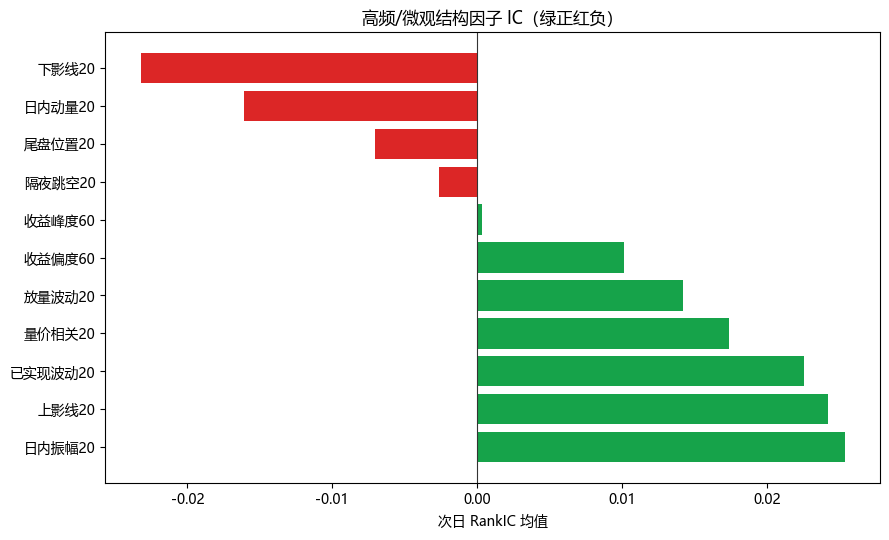

In [3]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(figsize=(9, 5.5))
colors = ['#dc2626' if x < 0 else '#16a34a' for x in res['IC']]
ax.barh(res.index, res['IC'], color=colors)
ax.axvline(0, color='#333', lw=0.8)
ax.set_xlabel('次日 RankIC 均值'); ax.set_title('高频/微观结构因子 IC（绿正红负）')
plt.tight_layout(); plt.show()

## 四、因子衰减：不同持有期表现

In [4]:
# 选 IC 最强的因子看衰减
best = res['IC'].abs().idxmax()
from factor_lab.evaluate import ic_decay
dec = ic_decay(hf[best], cl, ks=(1,3,5,10,20,60))
print('因子「%s」的 IC 衰减:' % best)
print(dec.round(4).to_string())

因子「日内振幅20」的 IC 衰减:
       IC均值      IR    IC胜率
持有期                        
1    0.0254  0.0925  0.5398
3    0.0236  0.0876  0.5243
5    0.0198  0.0734  0.5243
10   0.0146  0.0544  0.5024
20   0.0164  0.0594  0.5062
60   0.0150  0.0568  0.5509


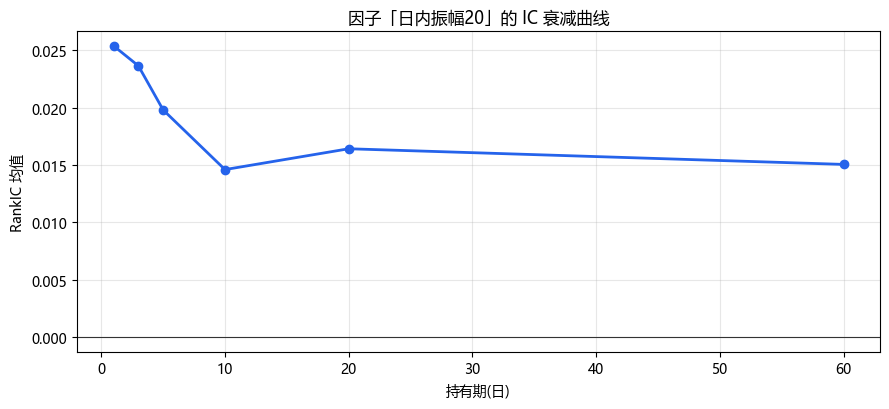

In [5]:
fig, ax = plt.subplots(figsize=(9,4.2))
ax.plot(dec.index, dec['IC均值'], 'o-', lw=2, color='#2563eb')
ax.axhline(0, color='#333', lw=0.8)
ax.set_xlabel('持有期(日)'); ax.set_ylabel('RankIC 均值')
ax.set_title('因子「%s」的 IC 衰减曲线' % best)
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 五、与 L1 因子的关系

- 高频因子多基于日内/分布信息，与 L1 的反转、低波因子部分相关但视角不同；
- 日频代理因子在沪深300 整体偏弱（真实高频因子需分钟数据，信息更细）；
- 价值在于低相关增量，需经正交后纳入合成（M2.3、M2.4 处理）。

## 六、小结与面试要点

- 用 OHLC 可构造分布、日内/隔夜、量价三类高频代理因子；IC/IR 与 L1 可对比。
- 真实高频因子依赖分钟/tick 数据，信号更细、衰减更快。

**面试高频：**
- 高频因子和普通量价因子的区别？（答：用日内/分布信息，频率高、衰减快、低相关）
- 已实现波动率怎么算？（答：高频收益的滚动标准差，低波因子取负向）
- 偏度因子为什么有效？（答：彩票偏好，高偏度股票未来收益往往偏低，故取负向）
- 日频数据能做高频因子吗？（答：可做代理，真实日内因子需分钟数据）

## 动手练习
1. 计算全部高频因子的 IC 并排序，找出最强与最弱；
2. 画出最强因子的 IC 衰减，判断它适合短周期还是长周期；
3. 思考：换成分钟数据后，哪些因子可以做得更精细。

---
下一节 **M2.2 基本面与事件因子**。